In [8]:
base_dir = r"/mnt/c/Users/baris/Desktop/Intelalgen_repo/modelling/model_results"
output_dir = r"/mnt/c/Users/baris/Desktop/Intelalgen_repo/analysis_and_explainability"

In [6]:
import os
import pandas as pd
from glob import glob

base_dir = r"/mnt/c/Users/baris/Desktop/Intelalgen_repo/modelling/model_results"


def collect_all_detailed_results(base_dir):
    """
    Finds all *_detailed.csv files recursively and concatenates them.
    """
    pattern = os.path.join(base_dir, "**", "*_detailed.csv")
    files = glob(pattern, recursive=True)

    if not files:
        raise ValueError("No detailed.csv files found!")

    all_dfs = []
    for f in files:
        try:
            df = pd.read_csv(f)
            df["source_file"] = f  # keep trace
            all_dfs.append(df)
        except Exception as e:
            print(f"Skipping {f}: {e}")

    return pd.concat(all_dfs, ignore_index=True)


def find_best_models(all_results_df):
    """
    For each genus:
    - best ROC-AUC
    - best PR-AUC
    """
    # Drop rows with NaNs in metrics
    df = all_results_df.dropna(subset=["roc_auc_mean", "pr_auc_mean"])

    # -------------------------
    # Best ROC-AUC per genus
    # -------------------------
    idx_roc = df.groupby("Genus")["roc_auc_mean"].idxmax()
    best_roc_df = df.loc[idx_roc].copy()

    # -------------------------
    # Best PR-AUC per genus
    # -------------------------
    idx_pr = df.groupby("Genus")["pr_auc_mean"].idxmax()
    best_pr_df = df.loc[idx_pr].copy()

    return best_roc_df, best_pr_df


def attach_model_paths(df, base_dir):
    """
    Adds model file path for each row based on Feature_Set + Genus
    """
    model_paths = []

    for _, row in df.iterrows():
        feature_set = row["Feature_Set"]
        genus = row["Genus"]

        model_path = os.path.join(
            base_dir,
            feature_set,
            "models",
            f"{feature_set}_{genus}.json"
        )

        model_paths.append(model_path)

    df["model_path"] = model_paths
    return df


def main_best_model_extraction(base_dir, output_dir):
    os.makedirs(output_dir, exist_ok=True)

    print("Collecting all detailed results...")
    all_results = collect_all_detailed_results(base_dir)

    print(f"Total rows collected: {len(all_results)}")

    print("Finding best models per genus...")
    best_roc_df, best_pr_df = find_best_models(all_results)

    print("Attaching model paths...")
    best_roc_df = attach_model_paths(best_roc_df, base_dir)
    best_pr_df = attach_model_paths(best_pr_df, base_dir)

    # Save
    roc_path = os.path.join(output_dir, "best_by_roc_auc.csv")
    pr_path = os.path.join(output_dir, "best_by_pr_auc.csv")

    best_roc_df.to_csv(roc_path, index=False)
    best_pr_df.to_csv(pr_path, index=False)

    print(f"\nSaved:")
    print(f"- ROC AUC best models: {roc_path}")
    print(f"- PR AUC best models: {pr_path}")

    return best_roc_df, best_pr_df


# -------------------------
# RUN
# -------------------------
if __name__ == "__main__":
    output_dir = os.path.join(base_dir, "best_models_summary")

    best_roc, best_pr = main_best_model_extraction(base_dir, output_dir)

Total rows collected: 729
Finding best models per genus...
Attaching model paths...

Saved:
- ROC AUC best models: /mnt/c/Users/baris/Desktop/Intelalgen_repo/modelling/model_results/best_models_summary/best_by_roc_auc.csv
- PR AUC best models: /mnt/c/Users/baris/Desktop/Intelalgen_repo/modelling/model_results/best_models_summary/best_by_pr_auc.csv


In [9]:
import os
import numpy as np
import pandas as pd
import xgboost as xgb
import shap

# USER CONTROLS
TOP_FEATURES_FOR_INTERACTIONS = 10
METRICS = ["roc_auc", "pr_auc"]


# LOADERS
def get_feature_set_dir(feature_set):
    """
    Checks whether the feature set folder lives directly inside base_dir
    or inside the intel_algen_xgboost subfolder.
    """
    intel_path = os.path.join(base_dir, "intel_algen_xgboost", feature_set)
    direct_path = os.path.join(base_dir, feature_set)

    if os.path.exists(intel_path):
        return intel_path
    return direct_path


def load_best_models_table(metric):
    path = os.path.join(
        base_dir,
        "best_models_summary",
        f"best_by_{metric}.csv"
    )

    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing best model file: {path}")

    return pd.read_csv(path)


def load_data(feature_set, genus):
    set_dir = get_feature_set_dir(feature_set)
    data_dir = os.path.join(
        set_dir,
        "models",
        "final_data",
        genus
    )

    X_path = os.path.join(data_dir, "X_full.parquet")
    y_path = os.path.join(data_dir, "y_full.npy")

    if not os.path.exists(X_path):
        raise FileNotFoundError(f"Missing X: {X_path}")
    if not os.path.exists(y_path):
        raise FileNotFoundError(f"Missing y: {y_path}")

    X = pd.read_parquet(X_path)
    y = np.load(y_path)

    return X, y


def load_model(feature_set, genus):
    set_dir = get_feature_set_dir(feature_set)
    model_path = os.path.join(
        set_dir,
        "models",
        f"{feature_set}_{genus}.json"
    )

    if not os.path.exists(model_path):
        raise FileNotFoundError(f"Missing model: {model_path}")

    model = xgb.Booster()
    model.load_model(model_path)

    return model


# GENUS PROCESSOR
def process_genus(row, metric, current_output_dir):
    genus = row["Genus"]
    feature_set = row["Feature_Set"]

    print(f"\nProcessing {genus} ({feature_set}) [{metric}]")

    try:
        X, y = load_data(feature_set, genus)
        model = load_model(feature_set, genus)
    except FileNotFoundError as e:
        print(f"⚠️ Skipping {genus}: {e}")
        return

    # Enforce float64 array for SHAP
    X_values = X.astype(np.float64).values
    feature_names = list(X.columns)

    genus_dir = os.path.join(current_output_dir, genus)
    os.makedirs(genus_dir, exist_ok=True)

    # SHAP EXPLAINER
    explainer = shap.TreeExplainer(model)
    shap_values = np.array(explainer.shap_values(X_values))

    # GLOBAL SHAP METRICS
    mean_abs = np.mean(np.abs(shap_values), axis=0)
    mean_signed = np.mean(shap_values, axis=0)
    mean_positive = np.mean(np.clip(shap_values, 0, None), axis=0)
    mean_negative = np.mean(np.clip(shap_values, None, 0), axis=0)

    # NORMALIZATION
    abs_total = np.sum(mean_abs)
    pos_total = np.sum(mean_positive)
    neg_total = np.sum(np.abs(mean_negative))

    summary_df = pd.DataFrame({
        "feature": feature_names,
        "mean_abs_shap": mean_abs,
        "mean_abs_shap_norm": mean_abs / abs_total if abs_total != 0 else mean_abs,
        "mean_signed_shap": mean_signed,
        "mean_signed_shap_norm": mean_signed / abs_total if abs_total != 0 else mean_signed,
        "mean_positive_shap": mean_positive,
        "mean_positive_shap_norm": mean_positive / pos_total if pos_total != 0 else mean_positive,
        "mean_negative_shap": mean_negative,
        "mean_negative_shap_norm": mean_negative / neg_total if neg_total != 0 else mean_negative
    })

    summary_df = summary_df.sort_values("mean_abs_shap", ascending=False)

    summary_path = os.path.join(genus_dir, f"shap_summary_{metric}.csv")
    summary_df.to_csv(summary_path, index=False)
    print(f"Saved summary: {summary_path}")

    # SELECT TOP FEATURES FOR INTERACTIONS
    top_features = summary_df.head(TOP_FEATURES_FOR_INTERACTIONS)["feature"].tolist()
    top_indices = [feature_names.index(f) for f in top_features]

    print("Computing SHAP interaction values...")
    interaction_values = np.array(explainer.shap_interaction_values(X_values))

    interactions = []
    for i in range(len(top_indices)):
        for j in range(i + 1, len(top_indices)):
            fi = top_indices[i]
            fj = top_indices[j]

            strength = np.mean(np.abs(interaction_values[:, fi, fj]))
            interactions.append({
                "feature_1": feature_names[fi],
                "feature_2": feature_names[fj],
                "interaction_strength": strength
            })

    interaction_df = pd.DataFrame(interactions).sort_values("interaction_strength", ascending=False)
    interaction_path = os.path.join(genus_dir, f"shap_interactions_{metric}.csv")
    interaction_df.to_csv(interaction_path, index=False)

    print(f"Saved interactions: {interaction_path}")
    print(f"{genus} [{metric}] done.")


# MAIN RUNNER
for metric in METRICS:
    print(f"\n===== PROCESSING: {metric} =====")

    current_output_dir = os.path.join(output_dir, "shap_results", f"by_{metric}")
    os.makedirs(current_output_dir, exist_ok=True)

    best_models = load_best_models_table(metric)

    for _, row in best_models.iterrows():
        process_genus(row, metric, current_output_dir)

print("\n✅ All genera processed for all metrics.")


===== PROCESSING: roc_auc =====

Processing Actinocyclus (set_14_mth_chem_lp_lcom_gp_gcom) [roc_auc]
Saved summary: /mnt/c/Users/baris/Desktop/Intelalgen_repo/analysis_and_explainability/shap_results/by_roc_auc/Actinocyclus/shap_summary_roc_auc.csv
Computing SHAP interaction values...
Saved interactions: /mnt/c/Users/baris/Desktop/Intelalgen_repo/analysis_and_explainability/shap_results/by_roc_auc/Actinocyclus/shap_interactions_roc_auc.csv
Actinocyclus [roc_auc] done.

Processing Anabaena (set_10_mth_chem_lcom_gcom) [roc_auc]
Saved summary: /mnt/c/Users/baris/Desktop/Intelalgen_repo/analysis_and_explainability/shap_results/by_roc_auc/Anabaena/shap_summary_roc_auc.csv
Computing SHAP interaction values...
Saved interactions: /mnt/c/Users/baris/Desktop/Intelalgen_repo/analysis_and_explainability/shap_results/by_roc_auc/Anabaena/shap_interactions_roc_auc.csv
Anabaena [roc_auc] done.

Processing Aphanizomenon (set_4_mth_chem_lcoo) [roc_auc]
Saved summary: /mnt/c/Users/baris/Desktop/Intelal

In [10]:
import os
import numpy as np
import pandas as pd
import xgboost as xgb

# USER CONTROLS
METRICS = ["roc_auc", "pr_auc"]


# LOADERS
def get_feature_set_dir(feature_set):
    """
    Checks whether the feature set folder lives directly inside base_dir
    or inside the intel_algen_xgboost subfolder.
    """
    intel_path = os.path.join(base_dir, "intel_algen_xgboost", feature_set)
    direct_path = os.path.join(base_dir, feature_set)

    if os.path.exists(intel_path):
        return intel_path
    return direct_path


def load_best_models_table(metric):
    path = os.path.join(
        base_dir,
        "best_models_summary",
        f"best_by_{metric}.csv"
    )

    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing: {path}")

    return pd.read_csv(path)


def load_data(feature_set, genus):
    set_dir = get_feature_set_dir(feature_set)
    data_dir = os.path.join(
        set_dir,
        "models",
        "final_data",
        genus
    )

    X_path = os.path.join(data_dir, "X_full.parquet")
    y_path = os.path.join(data_dir, "y_full.npy")

    if not os.path.exists(X_path):
        raise FileNotFoundError(f"Missing X: {X_path}")
    if not os.path.exists(y_path):
        raise FileNotFoundError(f"Missing y: {y_path}")

    X = pd.read_parquet(X_path)
    y = np.load(y_path)

    return X, y


def load_model(feature_set, genus):
    set_dir = get_feature_set_dir(feature_set)
    model_path = os.path.join(
        set_dir,
        "models",
        f"{feature_set}_{genus}.json"
    )

    if not os.path.exists(model_path):
        raise FileNotFoundError(f"Missing model: {model_path}")

    model = xgb.Booster()
    model.load_model(model_path)

    return model


# IMPORTANCE EXTRACTION
def extract_xgb_importance(model, feature_names):
    importance_types = [
        "weight",
        "gain",
        "cover",
        "total_gain",
        "total_cover"
    ]

    data = {"feature": feature_names}

    for imp_type in importance_types:
        scores = model.get_score(importance_type=imp_type)

        values = np.array([
            scores.get(f, 0) for f in feature_names
        ], dtype=float)

        data[imp_type] = values
        total = values.sum()

        if total == 0:
            data[f"{imp_type}_norm"] = values
        else:
            data[f"{imp_type}_norm"] = values / total

    return pd.DataFrame(data)


# GENUS PROCESSOR
def process_genus(row, metric, current_output_dir):
    genus = row["Genus"]
    feature_set = row["Feature_Set"]

    print(f"\nProcessing {genus} ({feature_set}) [{metric}]")

    try:
        X, y = load_data(feature_set, genus)
        model = load_model(feature_set, genus)
    except FileNotFoundError as e:
        print(f"⚠️ Skipping {genus}: {e}")
        return

    feature_names = list(X.columns)

    genus_dir = os.path.join(current_output_dir, genus)
    os.makedirs(genus_dir, exist_ok=True)

    # EXTRACT IMPORTANCE
    importance_df = extract_xgb_importance(model, feature_names)

    # SORT BY GAIN NORM
    importance_df = importance_df.sort_values("gain_norm", ascending=False)

    # SAVE
    output_path = os.path.join(genus_dir, f"xgboost_importance_{metric}.csv")
    importance_df.to_csv(output_path, index=False)

    print(f"Saved: {output_path}")
    print(f"{genus} [{metric}] completed.")


# MAIN RUNNER
for metric in METRICS:
    print(f"\n===== PROCESSING: {metric} =====")

    current_output_dir = os.path.join(output_dir, "xgboost_importance_results", f"by_{metric}")
    os.makedirs(current_output_dir, exist_ok=True)

    best_models = load_best_models_table(metric)

    for _, row in best_models.iterrows():
        process_genus(row, metric, current_output_dir)

print("\n✅ All genera processed for all metrics.")


===== PROCESSING: roc_auc =====

Processing Actinocyclus (set_14_mth_chem_lp_lcom_gp_gcom) [roc_auc]
Saved: /mnt/c/Users/baris/Desktop/Intelalgen_repo/analysis_and_explainability/xgboost_importance_results/by_roc_auc/Actinocyclus/xgboost_importance_roc_auc.csv
Actinocyclus [roc_auc] completed.

Processing Anabaena (set_10_mth_chem_lcom_gcom) [roc_auc]
Saved: /mnt/c/Users/baris/Desktop/Intelalgen_repo/analysis_and_explainability/xgboost_importance_results/by_roc_auc/Anabaena/xgboost_importance_roc_auc.csv
Anabaena [roc_auc] completed.

Processing Aphanizomenon (set_4_mth_chem_lcoo) [roc_auc]
Saved: /mnt/c/Users/baris/Desktop/Intelalgen_repo/analysis_and_explainability/xgboost_importance_results/by_roc_auc/Aphanizomenon/xgboost_importance_roc_auc.csv
Aphanizomenon [roc_auc] completed.

Processing Asterionella (set_1_mth_chem) [roc_auc]
Saved: /mnt/c/Users/baris/Desktop/Intelalgen_repo/analysis_and_explainability/xgboost_importance_results/by_roc_auc/Asterionella/xgboost_importance_roc_a

Final corrected plot saved to: /mnt/c/Users/baris/Desktop/Intelalgen_repo/analysis_and_explainability/images/overall_cv_distribution_final.png


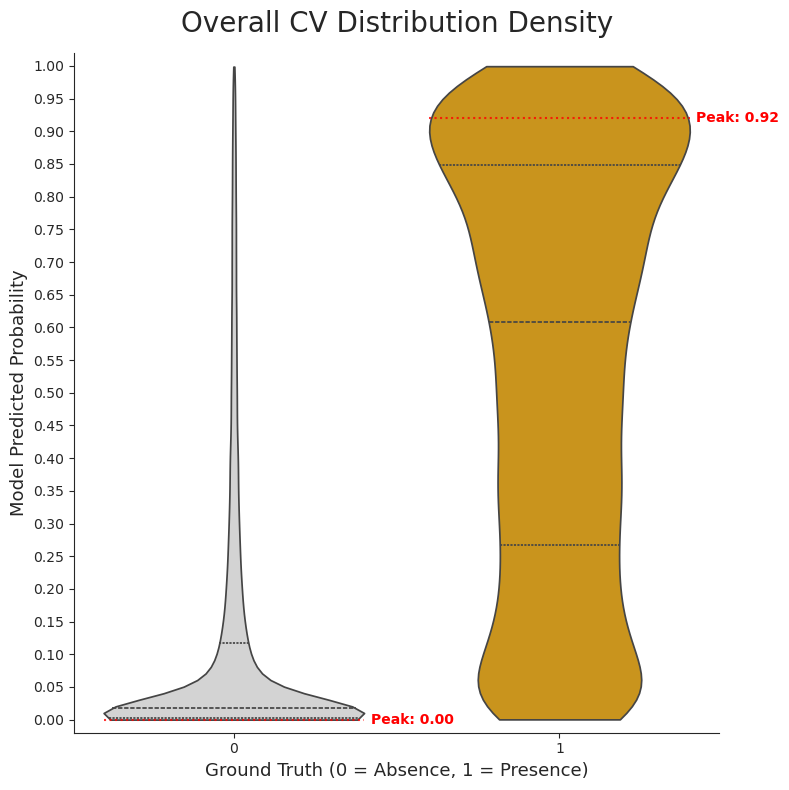

In [11]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Configuration using Global Notebook Variables ---
SUMMARY_CSV = os.path.join(base_dir, "best_models_summary", "best_by_pr_auc.csv")

# Save directly inside output_dir under images/
images_dir = os.path.join(output_dir, "images")
os.makedirs(images_dir, exist_ok=True)
SAVE_PATH = os.path.join(images_dir, "overall_cv_distribution_final.png")


def get_cv_genus_dir(feature_set, genus):
    """
    Checks whether the CV directory lives directly under base_dir
    or inside the intel_algen_xgboost subfolder.
    """
    path_intel = os.path.join(base_dir, "intel_algen_xgboost", feature_set, "models", "cv_data", genus)
    path_direct = os.path.join(base_dir, feature_set, "models", "cv_data", genus)

    if os.path.exists(path_intel):
        return path_intel
    return path_direct


def run_cv_aggregation_report():
    if not os.path.exists(SUMMARY_CSV):
        print(f"Summary CSV not found at: {SUMMARY_CSV}")
        return

    summary_df = pd.read_csv(SUMMARY_CSV)
    global_y_true, global_y_prob = [], []

    for _, row in summary_df.iterrows():
        genus_path = get_cv_genus_dir(row['Feature_Set'], row['Genus'])
        for fold in range(5):
            y_val_file = os.path.join(genus_path, f"fold_{fold}", "y_val.npy")
            y_pred_file = os.path.join(genus_path, f"fold_{fold}", "y_pred.npy")

            if os.path.exists(y_val_file) and os.path.getsize(y_val_file) > 0:
                global_y_true.extend(np.load(y_val_file))
                global_y_prob.extend(np.load(y_pred_file))

    if not global_y_true:
        print("⚠️ No valid CV prediction data found!")
        return

    df_plot = pd.DataFrame({'Actual': global_y_true, 'Probability': global_y_prob})
    df_plot['Actual'] = df_plot['Actual'].astype(int)

    # --- PEAK LOGIC ---
    # Find the peak for Absence (0)
    mode_0 = df_plot[df_plot['Actual'] == 0]['Probability'].round(2).mode()[0]
    
    # Find the peak for Presence (1) - focusing on successful detections (> 0.5)
    presence_data = df_plot[df_plot['Actual'] == 1]
    mode_1 = presence_data[presence_data['Probability'] > 0.5]['Probability'].round(2).mode()[0]

    # --- Plotting ---
    plt.figure(figsize=(8, 8))
    sns.set_style("ticks")
    palette_colors = {0: "lightgray", 1: "#E69F00"}

    sns.violinplot(
        x='Actual', 
        y='Probability', 
        data=df_plot, 
        hue='Actual', 
        palette=palette_colors, 
        inner="quartile", 
        cut=0, 
        legend=False
    )

    # Markers (matched to peaks)
    plt.hlines(y=mode_0, xmin=-0.4, xmax=0.4, color='red', linestyle=':', alpha=0.8)
    plt.hlines(y=mode_1, xmin=0.6, xmax=1.4, color='red', linestyle=':', alpha=0.8)
    
    plt.text(0.42, mode_0, f'Peak: {mode_0:.2f}', color='red', fontweight='bold', va='center')
    plt.text(1.42, mode_1, f'Peak: {mode_1:.2f}', color='red', fontweight='bold', va='center')

    plt.yticks(np.arange(0, 1.05, 0.05))
    plt.ylim(-0.02, 1.02)
    plt.title('Overall CV Distribution Density', fontsize=20, pad=15)
    plt.xlabel('Ground Truth (0 = Absence, 1 = Presence)', fontsize=13)
    plt.ylabel('Model Predicted Probability', fontsize=13)
    
    sns.despine()
    plt.tight_layout()
    plt.savefig(SAVE_PATH, dpi=300)
    print(f"Final corrected plot saved to: {SAVE_PATH}")
    plt.show()

# Execute plot generation directly inside the notebook
run_cv_aggregation_report()

In [12]:
import os
import re
import numpy as np
import pandas as pd

# --- Configuration using Global Notebook Variables ---
SUMMARY_CSV = os.path.join(base_dir, "best_models_summary", "best_by_pr_auc.csv")

# Save directly inside output_dir under tables/
tables_dir = os.path.join(output_dir, "tables")
os.makedirs(tables_dir, exist_ok=True)
SAVE_TABLE_PATH = os.path.join(tables_dir, "final_paper_performance_table.csv")


def clean_feature_set_name(name):
    """Removes 'set_1_', 'set_11_', etc. from the start of the string."""
    return re.sub(r'^set_\d+_', '', name)


def get_cv_genus_dir(feature_set, genus):
    """
    Checks whether the CV directory lives directly under base_dir
    or inside the intel_algen_xgboost subfolder.
    """
    path_intel = os.path.join(base_dir, "intel_algen_xgboost", feature_set, "models", "cv_data", genus)
    path_direct = os.path.join(base_dir, feature_set, "models", "cv_data", genus)

    if os.path.exists(path_intel):
        return path_intel
    return path_direct


def generate_final_table():
    if not os.path.exists(SUMMARY_CSV):
        print(f"Summary CSV not found at {SUMMARY_CSV}")
        return

    summary_df = pd.read_csv(SUMMARY_CSV)
    results = []

    print(f"Processing and cleaning data for {len(summary_df)} genera...")

    for _, row in summary_df.iterrows():
        genus = row['Genus']
        raw_f_set = row['Feature_Set']
        clean_f_set = clean_feature_set_name(raw_f_set)
        
        roc_auc = row['roc_auc_mean']
        pr_auc = row['pr_auc_mean']
        
        genus_path = get_cv_genus_dir(raw_f_set, genus)
        all_y_true = []

        # Aggregate Ground Truth (y_val) from all 5 folds
        for fold in range(5):
            y_val_file = os.path.join(genus_path, f"fold_{fold}", "y_val.npy")
            if os.path.exists(y_val_file) and os.path.getsize(y_val_file) > 0:
                try:
                    all_y_true.extend(np.load(y_val_file))
                except Exception:
                    continue

        if all_y_true:
            all_y_true = np.array(all_y_true).astype(int)
            count_1 = np.sum(all_y_true == 1)
            total = len(all_y_true)
            
            # Columns formatted for paper reporting
            results.append({
                'Genus': genus,
                'Feature_Combination': clean_f_set,
                'Presence_Ratio_%': round((count_1 / total) * 100, 2),
                'ROC_AUC': round(roc_auc, 4),
                'PR_AUC': round(pr_auc, 4)
            })

    if not results:
        print("⚠️ No valid CV ground truth files processed!")
        return

    report_df = pd.DataFrame(results)
    
    # Sort by Prevalence (Descending)
    report_df = report_df.sort_values(by='Presence_Ratio_%', ascending=False)

    # Save output
    report_df.to_csv(SAVE_TABLE_PATH, index=False)
    
    print("\n" + "=" * 85)
    print("FINAL CLEANED TABLE FOR PAPER (Sorted by Prevalence)")
    print(report_df.head(15).to_string(index=False))
    print("=" * 85)
    print(f"\nCSV saved to: {SAVE_TABLE_PATH}")

# Execute table generation directly inside notebook
generate_final_table()

Processing and cleaning data for 27 genera...

FINAL CLEANED TABLE FOR PAPER (Sorted by Prevalence)
           Genus Feature_Combination  Presence_Ratio_%  ROC_AUC  PR_AUC
      Rhodomonas            mth_chem             43.82   0.8013  0.7379
     Cryptomonas       mth_chem_lcom             39.33   0.7449  0.6575
        Ceratium       mth_chem_lcom             26.12   0.8715  0.6667
      Cyclotella            mth_chem             25.83   0.7661  0.5556
      Peridinium       mth_chem_lcom             25.83   0.8467  0.6910
      Fragilaria       mth_chem_lcom             24.94   0.7796  0.6019
     Gymnodinium            mth_chem             17.44   0.7967  0.5052
   Chlamydomonas            mth_chem             15.41   0.7624  0.4874
Chrysochromulina            mth_chem             14.10   0.7949  0.4500
       Dinobryon       mth_chem_lcom             11.94   0.8500  0.4564
    Planktothrix  mth_chem_lcom_lcoo             11.90   0.9142  0.7168
    Asterionella            mth_chem

In [14]:
import os
import pandas as pd

# Define output path within configured output_dir
summary_dir = os.path.join(output_dir, "summary_tables")
os.makedirs(summary_dir, exist_ok=True)
OUTPUT_FILE = os.path.join(summary_dir, "final_performance_comparison.csv")


def get_all_folders(search_dir):
    """Returns a list of all subdirectories within a given folder."""
    if not os.path.exists(search_dir):
        return []
    return [d for d in os.listdir(search_dir) if os.path.isdir(os.path.join(search_dir, d))]


def merge_summary_tables(base_dir, output_path):
    # Desired order for final aggregated comparison
    ordered_suffixes = [
        "mth_chem",
        "mth_chem_lcom", "mth_chem_lcom_gcom",
        "mth_chem_lp", "mth_chem_lp_gp",
        "mth_chem_lcoo", "mth_chem_lcoo_gcoo",
        "mth_chem_lp_lcom", "mth_chem_lp_lcom_gp", "mth_chem_lp_lcom_gcom", "mth_chem_lp_lcom_gp_gcom",
        "mth_chem_lcom_lcoo", "mth_chem_lcom_lcoo_gcom", "mth_chem_lcom_lcoo_gcoo", "mth_chem_lcom_lcoo_gcoo",
        "mth_chem_lp_lcoo", "mth_chem_lp_lcoo_gp", "mth_chem_lp_lcoo_gcoo", "mth_chem_lp_lcoo_gp_gcoo",
        "mth_chem_lp_lcom_lcoo", "mth_chem_lp_lcom_lcoo_gp", "mth_chem_lp_lcom_lcoo_gcom", 
        "mth_chem_lp_lcom_lcoo_gcoo", "mth_chem_lp_lcom_lcoo_gp_gcom", "mth_chem_lp_lcom_lcoo_gp_gcoo",
        "mth_chem_lp_lcom_lcoo_gcom_gcoo", "mth_chem_lp_lcom_lcoo_gp_gcom_gcoo"
    ]

    # Support direct directory structure or intel_algen_xgboost nesting
    intel_wrapper = os.path.join(base_dir, "intel_algen_xgboost")
    search_base = intel_wrapper if os.path.exists(intel_wrapper) else base_dir

    all_folders = get_all_folders(search_base)
    all_data = []

    for suffix in ordered_suffixes:
        target_folder = None
        for folder in all_folders:
            if folder.endswith(f"_{suffix}"):
                target_folder = folder
                break
        
        if target_folder:
            file_name = f"{target_folder}_summary.csv"
            file_path = os.path.join(search_base, target_folder, "logs", file_name)

            if os.path.exists(file_path):
                try:
                    df = pd.read_csv(file_path)
                    all_data.append(df)
                except Exception as e:
                    print(f"Error reading {file_path}: {e}")
            else:
                print(f"File not found: {file_path}")
        else:
            print(f"Could not find a folder for suffix: {suffix}")

    if all_data:
        final_table = pd.concat(all_data, ignore_index=True)
        
        # Ensure Feature_Set is the leading column
        if 'Feature_Set' in final_table.columns:
            cols = ['Feature_Set'] + [c for c in final_table.columns if c != 'Feature_Set']
            final_table = final_table[cols]
        
        final_table.to_csv(output_path, index=False)
        print(f"\nSuccessfully merged {len(all_data)} files into {output_path}")
        return final_table
    else:
        print("No data collected. Check if folder names match suffixes.")
        return None

# Execute merge directly inside notebook
merged_df = merge_summary_tables(base_dir, OUTPUT_FILE)


Successfully merged 27 files into /mnt/c/Users/baris/Desktop/Intelalgen_repo/analysis_and_explainability/summary_tables/final_performance_comparison.csv


In [15]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap

# ============================================================
# CONFIGURATION
# ============================================================

METRIC = "pr_auc"

TARGETS = [
    "Tabellaria",
    "Rhodomonas",
    "Anabaena",
    "Ceratium",
    "Oocystis"
]

NUM_PLOTS = 10   # top features per genus


# ============================================================
# LOADERS
# ============================================================

def get_feature_set_dir(feature_set):
    """
    Checks whether the feature set folder lives directly inside base_dir
    or inside the intel_algen_xgboost subfolder.
    """
    intel_path = os.path.join(base_dir, "intel_algen_xgboost", feature_set)
    direct_path = os.path.join(base_dir, feature_set)

    if os.path.exists(intel_path):
        return intel_path
    return direct_path


def load_best_models_table(metric):
    path = os.path.join(
        base_dir,
        "best_models_summary",
        f"best_by_{metric}.csv"
    )

    if not os.path.exists(path):
        raise FileNotFoundError(f"Missing best model file: {path}")

    return pd.read_csv(path)


def load_data(feature_set, genus):
    set_dir = get_feature_set_dir(feature_set)
    data_dir = os.path.join(
        set_dir,
        "models",
        "final_data",
        genus
    )

    X_path = os.path.join(data_dir, "X_full.parquet")
    y_path = os.path.join(data_dir, "y_full.npy")

    if not os.path.exists(X_path):
        raise FileNotFoundError(f"Missing X: {X_path}")
    if not os.path.exists(y_path):
        raise FileNotFoundError(f"Missing y: {y_path}")

    X = pd.read_parquet(X_path)
    y = np.load(y_path)

    return X, y


def load_model(feature_set, genus):
    set_dir = get_feature_set_dir(feature_set)
    model_path = os.path.join(
        set_dir,
        "models",
        f"{feature_set}_{genus}.json"
    )

    if not os.path.exists(model_path):
        raise FileNotFoundError(f"Missing model: {model_path}")

    model = xgb.Booster()
    model.load_model(model_path)

    return model


# ============================================================
# MAIN FUNCTION
# ============================================================

def generate_dependence_plots():

    print(f"🔎 Loading best models by {METRIC}...")

    try:
        df_best = load_best_models_table(METRIC)
    except Exception as e:
        print(f"❌ Could not load summary table: {e}")
        return

    df_targets = df_best[df_best["Genus"].isin(TARGETS)]

    if df_targets.empty:
        print("⚠️ No matching genera found in summary table.")
        return

    # Base output path under global output_dir
    plots_base_dir = os.path.join(output_dir, "dependence_plots", f"by_{METRIC}")
    os.makedirs(plots_base_dir, exist_ok=True)

    # ========================================================
    # LOOP THROUGH GENERA
    # ========================================================
    for _, row in df_targets.iterrows():

        genus = row["Genus"]
        feature_set = row["Feature_Set"]

        print(f"\n🎨 Processing genus: {genus}")

        try:
            # Load data + model
            X, y = load_data(feature_set, genus)
            model = load_model(feature_set, genus)

            # Ensure numeric float64 for SHAP
            X_numeric = X.astype(np.float64)

            # ====================================================
            # SHAP VALUES
            # ====================================================
            print("   → Computing SHAP values...")
            explainer = shap.TreeExplainer(model)
            shap_values = explainer.shap_values(X_numeric)

            # ====================================================
            # FEATURE IMPORTANCE (mean |SHAP|)
            # ====================================================
            mean_abs_shap = np.abs(shap_values).mean(axis=0)
            top_indices = np.argsort(mean_abs_shap)[-NUM_PLOTS:][::-1]
            top_features = X.columns[top_indices]

            # ====================================================
            # OUTPUT DIR FOR GENUS
            # ====================================================
            target_plot_dir = os.path.join(plots_base_dir, genus)
            os.makedirs(target_plot_dir, exist_ok=True)

            # ====================================================
            # PLOTTING
            # ====================================================
            print(f"   → Generating {NUM_PLOTS} dependence plots...")

            for feature in top_features:

                plt.figure(figsize=(8, 5))

                shap.dependence_plot(
                    feature,
                    shap_values,
                    X_numeric,
                    interaction_index=None,   # Pure single-feature effect
                    alpha=0.4,                 # Smoother look
                    dot_size=8,
                    show=False
                )

                plt.title(f"{genus} – SHAP Dependence: {feature}")

                # Clean filename
                clean_fname = "".join(
                    [c if c.isalnum() else "_" for c in feature]
                )

                save_path = os.path.join(
                    target_plot_dir,
                    f"{clean_fname}_dependence.png"
                )

                plt.savefig(save_path, bbox_inches='tight', dpi=150)
                plt.close()

            print(f"✅ Saved {NUM_PLOTS} plots → {target_plot_dir}")

        except Exception as e:
            print(f"❌ Error processing {genus}: {e}")

# Execute plot generator directly in notebook cell
generate_dependence_plots()

🔎 Loading best models by pr_auc...

🎨 Processing genus: Anabaena
   → Computing SHAP values...
   → Generating 10 dependence plots...
✅ Saved 10 plots → /mnt/c/Users/baris/Desktop/Intelalgen_repo/analysis_and_explainability/dependence_plots/by_pr_auc/Anabaena

🎨 Processing genus: Ceratium
   → Computing SHAP values...
   → Generating 10 dependence plots...


/home/baris/miniconda3/envs/shap_subspace/lib/python3.11/site-packages/shap/plots/_scatter.py:641: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(figsize=figsize)


✅ Saved 10 plots → /mnt/c/Users/baris/Desktop/Intelalgen_repo/analysis_and_explainability/dependence_plots/by_pr_auc/Ceratium

🎨 Processing genus: Oocystis
   → Computing SHAP values...
   → Generating 10 dependence plots...


/tmp/ipykernel_23542/3773134160.py:164: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(8, 5))


✅ Saved 10 plots → /mnt/c/Users/baris/Desktop/Intelalgen_repo/analysis_and_explainability/dependence_plots/by_pr_auc/Oocystis

🎨 Processing genus: Rhodomonas
   → Computing SHAP values...
   → Generating 10 dependence plots...
✅ Saved 10 plots → /mnt/c/Users/baris/Desktop/Intelalgen_repo/analysis_and_explainability/dependence_plots/by_pr_auc/Rhodomonas

🎨 Processing genus: Tabellaria
   → Computing SHAP values...
   → Generating 10 dependence plots...
✅ Saved 10 plots → /mnt/c/Users/baris/Desktop/Intelalgen_repo/analysis_and_explainability/dependence_plots/by_pr_auc/Tabellaria


...

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt
import shap
import os
import numpy as np
import pandas as pd
import xgboost as xgb

# ============================================================
# CONFIG
# ============================================================

base_dir = base_dir

METRIC = "pr_auc"

TARGETS = [
    "Tabellaria",
    "Rhodomonas",
    "Anabaena",
    "Ceratium",
    "Oocystis"
]

TOP_K = 5

COLORS = ["red", "blue", "green", "purple", "orange"]


# ============================================================
# LOADERS
# ============================================================

def load_best_models_table(metric):
    return pd.read_csv(
        os.path.join(base_dir, "best_models_summary", f"best_by_{metric}.csv")
    )


def load_data(feature_set, genus):
    path = os.path.join(base_dir, feature_set, "models", "final_data", genus)
    X = pd.read_parquet(os.path.join(path, "X_full.parquet"))
    y = np.load(os.path.join(path, "y_full.npy"))
    return X, y


def load_model(feature_set, genus):
    model = xgb.Booster()
    model.load_model(
        os.path.join(base_dir, feature_set, "models", f"{feature_set}_{genus}.json")
    )
    return model


# ============================================================
# CONTINUOUS FILTER
# ============================================================

def is_continuous(series):
    if not np.issubdtype(series.dtype, np.number):
        return False
    if series.dropna().nunique() <= 2:
        return False
    return True


# ============================================================
# MAIN PLOT (OVERLAY VERSION)
# ============================================================

def run():

    df = load_best_models_table(METRIC)
    df = df[df["Genus"].isin(TARGETS)]

    for _, row in df.iterrows():

        genus = row["Genus"]
        feature_set = row["Feature_Set"]

        print(f"\n🚀 {genus}")

        X, y = load_data(feature_set, genus)
        model = load_model(feature_set, genus)

        explainer = shap.TreeExplainer(model)
        shap_values = explainer.shap_values(X)

        # ====================================================
        # FEATURE IMPORTANCE
        # ====================================================
        importance = np.abs(shap_values).mean(axis=0)

        feature_rank = pd.DataFrame({
            "feature": X.columns,
            "importance": importance
        }).sort_values("importance", ascending=False)

        # ====================================================
        # TOP CONTINUOUS FEATURES
        # ====================================================
        selected = []
        for f in feature_rank["feature"]:
            if is_continuous(X[f]):
                selected.append(f)
            if len(selected) == TOP_K:
                break

        # ====================================================
        # FIGURE (SINGLE AXES)
        # ====================================================
        plt.figure(figsize=(10, 6))

        legend_lines = []

        for i, f in enumerate(selected):

            x_raw = X[f].astype(float).values
            y_vals = shap_values[:, X.columns.get_loc(f)]

            x_min = np.nanmin(x_raw)
            x_max = np.nanmax(x_raw)

            if x_min == x_max:
                continue

            # normalize
            x_norm = (x_raw - x_min) / (x_max - x_min) * 100

            # sort for smooth curve
            order = np.argsort(x_norm)
            x_sorted = x_norm[order]
            y_sorted = y_vals[order]

            # scatter
            """
            plt.scatter(
                x_sorted,
                y_sorted,
                color=COLORS[i],
                alpha=0.4,
                s=10
            )
            """
            # trend line
            z = np.polyfit(x_sorted, y_sorted, 3)
            p = np.poly1d(z)
            xs = np.linspace(0, 100, 300)
            plt.plot(xs, p(xs), color=COLORS[i], linewidth=2)

            legend_lines.append(
                f"{f} (min:{x_min:.2f}, max:{x_max:.2f})"
            )

        # ====================================================
        # FINAL FORMATTING
        # ====================================================
        plt.xlim(0, 100)
        plt.xlabel("Feature value (0–100 normalized)")
        plt.ylabel("SHAP value")

        plt.title(f"{genus} – Overlay SHAP Dependence (Top 5 Continuous Features)")

        plt.legend(legend_lines, fontsize=8, loc="best")

        # save
        out_dir = os.path.join(base_dir, "SHAP_OVERLAY", genus)
        os.makedirs(out_dir, exist_ok=True)

        plt.savefig(
            os.path.join(out_dir, f"{genus}_overlay_shap.png"),
            dpi=200,
            bbox_inches="tight"
        )
        plt.close()

        print(f"✅ Saved {genus}")


# ============================================================
# RUN
# ============================================================

if __name__ == "__main__":
    run()


🚀 Anabaena
✅ Saved Anabaena

🚀 Ceratium
✅ Saved Ceratium

🚀 Oocystis
✅ Saved Oocystis

🚀 Rhodomonas
✅ Saved Rhodomonas

🚀 Tabellaria
✅ Saved Tabellaria


In [ ]:
# ============================================================
# SHAP VALUE EXPORTER
# ONE EXCEL FILE PER GENUS
# POSITIVE + NEGATIVE SHAP VALUES MERGED
# ============================================================

import os
import numpy as np
import pandas as pd
import shap
import xgboost as xgb


# CONFIG

OUTPUT_DIR = os.path.join(
    base_dir,
    "shap_value_exports"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

METRIC = "pr_auc"

TARGETS = [
    "Tabellaria",
    "Rhodomonas",
    "Anabaena",
    "Ceratium",
    "Oocystis"
]

NUM_FEATURES = 20

# LOADERS

def load_best_models_table(metric):

    path = os.path.join(
        base_dir,
        "best_models_summary",
        f"best_by_{metric}.csv"
    )

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Missing best model file: {path}"
        )

    return pd.read_csv(path)


def load_data(feature_set, genus):

    data_dir = os.path.join(
        base_dir,
        feature_set,
        "models",
        "final_data",
        genus
    )

    X_path = os.path.join(data_dir, "X_full.parquet")
    y_path = os.path.join(data_dir, "y_full.npy")

    if not os.path.exists(X_path):
        raise FileNotFoundError(
            f"Missing X: {X_path}"
        )

    if not os.path.exists(y_path):
        raise FileNotFoundError(
            f"Missing y: {y_path}"
        )

    X = pd.read_parquet(X_path)
    y = np.load(y_path)

    return X, y


def load_model(feature_set, genus):

    model_path = os.path.join(
        base_dir,
        feature_set,
        "models",
        f"{feature_set}_{genus}.json"
    )

    if not os.path.exists(model_path):
        raise FileNotFoundError(
            f"Missing model: {model_path}"
        )

    model = xgb.Booster()
    model.load_model(model_path)

    return model


# FEATURE NAME CLEANER

def clean_feature_name(feature_name):

    cleaned = feature_name

    # Simplify LCoO / GCoO names
    if cleaned.startswith("LCoO_") or cleaned.startswith("GCoO_"):

        if "_with_" in cleaned:
            cleaned = cleaned.split("_with_")[0]

    # Remove measurement suffix
    cleaned = cleaned.replace("_mg_per_l", "")

    # Replace invalid Excel characters
    cleaned = "".join(
        c if c.isalnum() else "_"
        for c in cleaned
    )

    return cleaned

# MAIN FUNCTION

def export_shap_values():

    df_best = load_best_models_table(METRIC)

    df_targets = df_best[
        df_best["Genus"].isin(TARGETS)
    ]

    if df_targets.empty:
        return

    # ONE FILE PER GENUS

    for _, row in df_targets.iterrows():

        genus = row["Genus"]
        feature_set = row["Feature_Set"]

        # Load data and model

        X, y = load_data(
            feature_set,
            genus
        )

        model = load_model(
            feature_set,
            genus
        )

        # Sample IDs

        sample_ids = [
            f"sample_{i + 1}"
            for i in range(len(X))
        ]

        # Calculate SHAP values

        explainer = shap.TreeExplainer(model)

        shap_values = explainer.shap_values(X)

        # Select top features

        mean_abs_shap = np.abs(
            shap_values
        ).mean(axis=0)

        top_indices = np.argsort(
            mean_abs_shap
        )[-NUM_FEATURES:][::-1]

        top_features = X.columns[top_indices]

        # Create ONE Excel file for this genus

        output_excel = os.path.join(
            OUTPUT_DIR,
            f"{genus}_shap_values.xlsx"
        )

        with pd.ExcelWriter(
            output_excel,
            engine="openpyxl"
        ) as writer:

            # One sheet per feature
            # Positive and negative SHAP values are merged

            for feature in top_features:

                feature_idx = X.columns.get_loc(feature)

                df_feature = pd.DataFrame({
                    "sample_id": sample_ids,
                    "value": X[feature].values,
                    "shap_value": shap_values[:, feature_idx]
                })

                # Sort by SHAP value so that negative and
                # positive contributions are both retained
                df_feature = df_feature.sort_values(
                    by="shap_value",
                    ascending=True
                )

                # Clean feature name for Excel sheet
                clean_feature = clean_feature_name(
                    feature
                )

                # Excel sheet names are limited to 31 characters
                sheet_name = clean_feature[:31]

                df_feature.to_excel(
                    writer,
                    sheet_name=sheet_name,
                    index=False
                )

# RUN

if __name__ == "__main__":

    export_shap_values()


In [ ]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
from scipy.stats import spearmanr


# ============================================================
# LOAD SHAP EXCEL FILES
# ============================================================

dataset_path = "/content/drive/MyDrive/Lavoro/Università/Mathematics/IntelAlgen"

shap_dir = os.path.join(
    dataset_path,
    "shap_value_exports"
)

shap_files = []

for file in os.listdir(shap_dir):
    if file.endswith("_shap_values.xlsx"):
        shap_files.append(
            os.path.join(shap_dir, file)
        )


# Load every sheet from every genus file
dfs_with_pos_sheets = {}

for file_path in shap_files:

    xls = pd.ExcelFile(file_path)

    base_name = os.path.basename(file_path).replace(
        "_shap_values.xlsx",
        ""
    )

    for sheet_name in xls.sheet_names:

        df = pd.read_excel(
            xls,
            sheet_name=sheet_name
        )

        key = f"{base_name}_{sheet_name}"

        dfs_with_pos_sheets[key] = df


# ============================================================
# CALCULATE SPEARMAN CORRELATIONS
# ============================================================

spearman_results = {}

for name, df in dfs_with_pos_sheets.items():

    if "value" not in df.columns or "shap_value" not in df.columns:
        continue

    correlation, p_value = spearmanr(
        df["value"],
        abs(df["shap_value"])
    )

    spearman_results[name] = {
        "correlation": correlation,
        "p_value": p_value
    }


# ============================================================
# KEEP STATISTICALLY SIGNIFICANT RELATIONSHIPS
# ============================================================

modified_spearman_results = {}

for key, value in spearman_results.items():

    # New filename structure:
    # Anabaena_Asterionella_pos
    #
    # The previous code expected:
    # Anabaena_shap_values_merged_Asterionella_pos

    parts = key.rsplit("_", 1)

    if len(parts) != 2:
        continue

    genus = parts[0]
    feature = parts[1]

    # Remove _pos / _neg from sheet name
    feature = feature.replace("_pos", "").replace("_neg", "")

    new_key = f"{feature} <- {genus}"

    modified_spearman_results[new_key] = value


weighted_directed_network_edges = []

for key, data in modified_spearman_results.items():

    if (
        "p_value" in data
        and not pd.isna(data["p_value"])
        and data["p_value"] < 0.05
    ):

        try:
            source_node, target_node = key.split(" <- ")

            weighted_directed_network_edges.append(
                (
                    target_node.strip(),
                    source_node.strip(),
                    data["correlation"]
                )
            )

        except ValueError:
            continue


# ============================================================
# MAP FEATURE NAMES
# ============================================================

source_mapping = {
    "Temperature (°C)": "temperature_celsius",
    "Dissolved Silica": "dissolved_silica_combined",
    "pH": "ph",
    "Depth (m)": "depth_m",
    "Total Phosphorus": "total_phosphorus_combined",
    "Chlorophyll-a (µg/L)": "chlorophyll_a_ug_per_l",
    "Phaeophytin (µg/L)": "phaeophytin_ug_per_l",
    "Ammonium": "ammonium",
    "June": "month_6",
    "August": "month_8",
    "Conductivity (µs/cm)": "conductivity_us_per_cm",
    "Total Nitrogen": "total_nitrogen",
    "Oxygen": "oxygen",
    "April": "month_4",
    "September": "month_9",
    "March": "month_3",
    "November": "month_11",
    "July": "month_7",
    "Anabaena": "Anabaena",
    "Asterionella": "Asterionella",
    "gcom": "GCom",
    "Gymnodinium": "Gymnodinium",
    "lcom": "LCom",
    "Aulacoseira": "Aulacoseira",
    "Cryptomonas": "Cryptomonas",
    "May": "month_5",
    "October": "month_10",
}

reverse_source_mapping = {
    value: key
    for key, value in source_mapping.items()
}


mapped_weighted_directed_network_edges = []

for target_node, source_node, correlation in weighted_directed_network_edges:

    mapped_target_node = reverse_source_mapping.get(
        target_node,
        target_node
    )

    mapped_source_node = reverse_source_mapping.get(
        source_node,
        source_node
    )

    mapped_weighted_directed_network_edges.append(
        (
            mapped_target_node,
            mapped_source_node,
            correlation
        )
    )


# ============================================================
# CREATE CORRELATION MATRIX
# ============================================================

edges_df_mapped = pd.DataFrame(
    mapped_weighted_directed_network_edges,
    columns=["Feature", "Genus", "ρ"]
)

pivot_df = edges_df_mapped.pivot_table(
    index="Feature",
    columns="Genus",
    values="ρ",
    fill_value=0
)


# ============================================================
# CREATE CLUSTERED HEATMAP
# ============================================================

row_linkage = sch.linkage(
    pivot_df,
    method="ward"
)

col_linkage = sch.linkage(
    pivot_df.T,
    method="ward"
)

g = sns.clustermap(
    pivot_df,
    row_linkage=row_linkage,
    col_linkage=col_linkage,
    cmap="RdBu",
    center=0,
    figsize=(12, 10),
    cbar_kws={"label": r"$r_{s}$"}
)


# ============================================================
# FORMAT HEATMAP
# ============================================================

heatmap_ax = g.ax_heatmap

plt.setp(
    heatmap_ax.get_xticklabels(),
    fontsize=10
)

plt.setp(
    heatmap_ax.get_yticklabels(),
    fontsize=10
)

heatmap_ax.set_xlabel(
    heatmap_ax.get_xlabel(),
    fontsize=16,
    fontweight="bold"
)

heatmap_ax.set_ylabel(
    heatmap_ax.get_ylabel(),
    fontsize=16,
    fontweight="bold"
)

g.ax_cbar.set_ylabel(
    r"$r_{s}$",
    fontsize=12,
    fontweight="bold"
)


# ============================================================
# SAVE HEATMAP
# ============================================================

output_plot_path = os.path.join(
    dataset_path,
    "clustered_heatmap_shap.png"
)

g.savefig(
    output_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
